# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 06: Model Selection and Scoring

**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below (see [`agents.md`](../agents.md)).


### Planned Steps & Workflow (Referencing `docs/project_cv_workflow.html`)
- **1. Comprehensive CV Comparison (Workflow Step 5 & 6)**:
  - Assemble the CV results table comparing all candidate models from Notebooks 03, 04, and 05 (the full model ladder) on the shared expanding-window CV splits.
  - Display CV mean error and SE ($\text{SD}/\sqrt{8}$) for each model.
- **2. Winning Model Selection (Workflow Step 6)**:
  - Apply selection criteria: lowest mean CV error or the **One-SE Rule** ($\text{threshold} = \text{min}(\text{CV error}) + \text{SE}$).
  - Formally declare the winning champion model prior to opening the test set.
- **3. Refit Winner on All Training Data (Workflow Step 6)**:
  - Refit the winning model specification on the entire training set (all folds combined).
  - Freeze the model parameters, preprocessing, and hyperparameters.
- **4. Establish Audit Pass Criteria (Workflow "Did the audit pass?")**:
  - Fix pass criteria before scoring:
    1. Test score agrees with CV: test error falls roughly within $\text{CV mean} \pm 2\,\text{SE}$.
    2. Model beats baseline: test error clearly lower than training mean predictor $\text{MSE}_{\text{baseline}} = \frac{1}{n_{\text{test}}} \sum_{i \in \text{test}} (y_i - \bar{y}_{\text{train}})^2$.
- **5. Single Test Set Audit (Workflow Step 7)**:
  - Apply the identical Notebook 02 base processing to the test set (same dropped columns, fixed dummy levels), then the winning model's Notebook 04 transforms.
  - Unlock the holdout test set (2012-10-19 to 2012-12-31) and score the winning model **once**.
  - Report final out-of-sample metrics (count-scale RMSE, MAE, $R^2$).
  - Evaluate whether the audit passed and analyze performance during external shocks (e.g. Hurricane Sandy on Oct 29–30, 2012).
- **6. Final Full Refit on All Data (Workflow Step 8)**:
  - Refit the winning model specification on train + test combined ($N = 17,379$).
  - For an OLS winner, use `statsmodels` for final coefficient tables and conditional standard errors/confidence intervals. For a penalised winner, retain its exact estimator and report coefficients without substituting invalid ordinary OLS inference.
  - Retain Step 5 test score as the final reported out-of-sample performance figure.


## 1. Setup, declared metric and selection configuration

*Code: Generated by AI Assistant*

Implementation: comparison uses count-scale mean fold MSE; CV RMSE is its square root, and SE(MSE) is sample SD of the eight fold MSEs divided by sqrt(8). The configured rule is lowest mean CV MSE (one of the planned alternatives). No test result is used for selection. The exported scores are tuning/selection scores, not a nested-CV estimate of generalisation. The planned ±2 SE audit band is a heuristic, not a calibrated prediction interval for a later time block.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, warnings, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/data_utils.py').exists())
sys.path.insert(0, str(ROOT))
from src.data_utils import load_train_base, load_train, load_test, SPLIT_DATE
from src.cv_utils import get_cv_splitter
OUT = Path(os.environ.get('DSA211_06_OUTPUT_DIR', str(ROOT/'data')))
OUT.mkdir(parents=True, exist_ok=True)
SELECTION_RULE = 'minimum_mean_mse'
assert SELECTION_RULE == 'minimum_mean_mse'
# Required by the supplied audit plan; also report the numerical baseline improvement.
MIN_BASELINE_GAIN = 0.0
base_df = load_train_base().reset_index(drop=True)
raw_train = load_train().reset_index(drop=True)
FEATURE_COLS = [c for c in base_df if c not in ['dteday','cnt']]
HR_COLS = [c for c in FEATURE_COLS if c.startswith('hr_')]
y_train = base_df['cnt'].to_numpy(dtype=float)
assert base_df['dteday'].is_monotonic_increasing
assert (base_df['dteday'] < SPLIT_DATE).all() and (y_train > 0).all()
cv = get_cv_splitter(base_df['dteday'])
folds = list(cv.split(base_df))
months = [base_df['dteday'].iloc[va].min().strftime('%Y-%m') for tr, va in folds]
assert len(folds) == 8
for tr, va in folds:
    assert base_df['dteday'].iloc[tr].max() < base_df['dteday'].iloc[va].min()
print('Rule:', SELECTION_RULE, '| metric: count-scale MSE | folds:', months)
print('Training rows:', len(base_df), '| test set not loaded')

Rule: minimum_mean_mse | metric: count-scale MSE | folds: ['2012-02', '2012-03', '2012-04', '2012-05', '2012-06', '2012-07', '2012-08', '2012-09']
Training rows: 15643 | test set not loaded


## 2. Reproduce preprocessing and candidate specifications from Notebooks 02–05

*Code: Generated by AI Assistant*

The fixed category levels and column order match Notebook 02. Polynomial features are uncentred degree-2 terms, matching the fitted Notebook 04/05 specifications. Scaling is fitted inside each training fold. Notebook 03 drops the redundant workingday main effect; the exported Notebook 04/05 M1 reference retains it. The training-only check below verifies prediction equivalence, rather than treating these as different model families.

In [2]:
LEVELS = {'hr': list(range(24)), 'mnth': list(range(1,13)),
          'weekday': list(range(7)), 'weathersit': [1,2,3,4]}
KEEP = ['yr','holiday','workingday','temp','hum','windspeed']
def base_process(raw):
    raw = raw.reset_index(drop=True)
    for c, levels in LEVELS.items():
        if not raw[c].isin(levels).all():
            raise ValueError(f'Unexpected/missing category in {c}')
    cats = pd.DataFrame({c: pd.Categorical(raw[c], categories=v) for c,v in LEVELS.items()})
    dummy = pd.get_dummies(cats, prefix=list(LEVELS), drop_first=True, dtype=int)
    result = pd.concat([raw[['dteday','cnt']], dummy, raw[KEEP]], axis=1)
    assert list(result.columns) == list(base_df.columns)
    assert not result.isna().any().any()
    return result
pd.testing.assert_frame_equal(base_process(raw_train), base_df, check_dtype=False)

def design(base, space):
    X = base[FEATURE_COLS].astype(float).copy()
    if space in ['m3','m4']:
        for c in ['temp','hum','windspeed']:
            X[f'{c}^2'] = X[c] ** 2
    if space == 'm4':
        inter = X[HR_COLS].mul(X['workingday'], axis=0)
        inter.columns = [f'{c}:workingday' for c in HR_COLS]
        X = pd.concat([X, inter], axis=1)
    return X

def make_estimator(spec):
    if spec['kind'] == 'ols':
        return Pipeline([('reg', LinearRegression())])
    reg = (Ridge(alpha=spec['alpha']) if spec['kind']=='ridge'
           else Lasso(alpha=spec['alpha'], max_iter=20000))
    return Pipeline([('scale', StandardScaler()), ('reg', reg)])

def fit_candidate(spec, base):
    X = design(base, spec['space'])
    y = base['cnt'].to_numpy(dtype=float)
    target = np.log(y) if spec['log_target'] else y
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        estimator = make_estimator(spec).fit(X, target)
    sigma2 = None
    if spec['log_target']:
        resid = target - estimator.predict(X)
        if spec['kind']=='ols':
            p = np.linalg.matrix_rank(np.column_stack([np.ones(len(X)),X]))
        elif spec['kind']=='ridge':
            p = X.shape[1] + 1  # Notebook 05 convention, not effective Ridge df
        else:
            p = np.count_nonzero(estimator.named_steps['reg'].coef_) + 1
        assert len(X) > p
        sigma2 = float(resid @ resid / (len(X)-p))
    return estimator, sigma2

def predict_count(spec, estimator, sigma2, base):
    pred = estimator.predict(design(base, spec['space']))
    pred = np.exp(pred + sigma2/2) if spec['log_target'] else pred
    assert np.isfinite(pred).all()
    return pred

specs = {f'M{i} OLS': {'kind':'ols','space':space,'alpha':None,'log_target':i>1}
         for i,space in enumerate(['base','base','m3','m4'],1)}
# Exact grid entries identified by Notebook 05's saved tuning summary (not rounded printed values).
ridge_grid = np.logspace(-4,4,41)
lasso_grid = np.logspace(-5,-0.5,31)
choices = {('ridge','base'):(37,38), ('ridge','m4'):(0,39),
           ('lasso','base'):(24,26), ('lasso','m4'):(16,24)}
for (kind,space), indices in choices.items():
    grid = ridge_grid if kind=='ridge' else lasso_grid
    for rule,idx in zip(['min','1se'],indices):
        specs[f'{kind.capitalize()} {space} ({rule})'] = {
            'kind':kind,'space':space,'alpha':float(grid[idx]),'log_target':True}
display(pd.DataFrame(specs).T)
# Verify Notebook 03's cleaned M1 has the same fitted values as the exported M1 reference.
X = design(base_df,'base')
a = LinearRegression().fit(X,y_train).predict(X)
b = LinearRegression().fit(X.drop(columns='workingday'),y_train).predict(X.drop(columns='workingday'))
np.testing.assert_allclose(a,b,atol=1e-6,rtol=1e-7)

,kind,space,alpha,log_target
M1 OLS,ols,base,None,False
M2 OLS,ols,base,None,True
M3 OLS,ols,m3,None,True
M4 OLS,ols,m4,None,True
Ridge base (min),ridge,base,2511.886432,True
Ridge base (1se),ridge,base,3981.071706,True
Ridge m4 (min),ridge,m4,0.0001,True
Ridge m4 (1se),ridge,m4,6309.573445,True
Lasso base (min),lasso,base,0.039811,True
Lasso base (1se),lasso,base,0.079433,True


## 3. Comprehensive CV comparison and reproducibility checks

*Code: Generated by AI Assistant*

,cv_mse,sd_mse,folds,se_mse,cv_rmse,se_rmse_delta
model,,,,,,
Lasso m4 (min),12259.727,11208.300,8,3962.733,110.724,17.895
M4 OLS,13330.003,12377.965,8,4376.271,115.456,18.952
Ridge m4 (min),13330.450,12378.439,8,4376.439,115.458,18.953
Lasso m4 (1se),14891.461,5839.631,8,2064.621,122.031,8.459
Ridge m4 (1se),16093.462,5774.152,8,2041.471,126.860,8.046
M1 OLS,17125.202,5324.926,8,1882.646,130.863,7.193
Ridge base (min),18331.616,5318.015,8,1880.202,135.394,6.943
Ridge base (1se),18677.756,5191.409,8,1835.440,136.667,6.715
Lasso base (min),20160.761,7721.430,8,2729.938,141.989,9.613


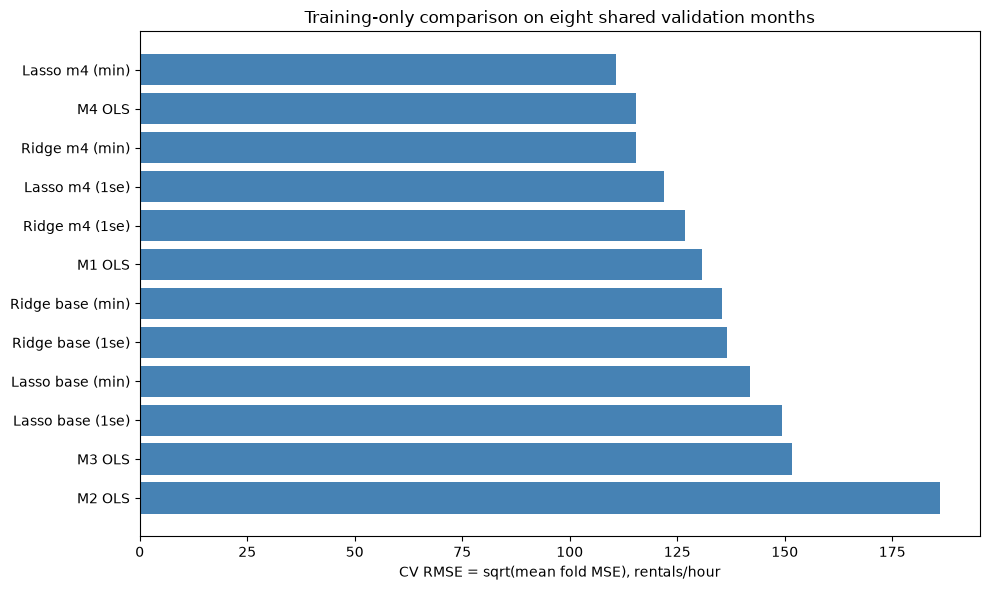

In [3]:
export_path = ROOT/'data/cv_results_05_regularization.csv'
export = pd.read_csv(export_path)
assert set(export['model']) == set(specs)
assert not export.duplicated(['model','fold']).any()
assert np.isfinite(export['mse']).all() and (export['mse'] >= 0).all()
for label,g in export.groupby('model'):
    g = g.sort_values('fold')
    assert g['fold'].tolist() == list(range(1,9))
    assert g['val_month'].tolist() == months
# Recompute only the fixed exported candidates; do not re-tune on these results.
checks = []
for label,spec in specs.items():
    expected = export[export['model']==label].sort_values('fold')['mse'].to_numpy()
    actual = []
    for tr,va in folds:
        est,s2 = fit_candidate(spec,base_df.iloc[tr])
        pred = predict_count(spec,est,s2,base_df.iloc[va])
        actual.append(mean_squared_error(y_train[va],pred))
    np.testing.assert_allclose(actual,expected,rtol=2e-4,atol=0.05,
                               err_msg=f'Export mismatch: {label}; stop before test access')
    checks.append({'model':label,'max_abs_MSE_difference':float(np.max(np.abs(np.array(actual)-expected)))})
summary = export.groupby('model')['mse'].agg(['mean','std','count'])
summary.columns = ['cv_mse','sd_mse','folds']
summary['se_mse'] = summary['sd_mse']/np.sqrt(summary['folds'])
summary['cv_rmse'] = np.sqrt(summary['cv_mse'])
summary['se_rmse_delta'] = summary['se_mse']/(2*summary['cv_rmse'])
summary = summary.sort_values('cv_mse')
display(summary.round(3))
summary.to_csv(OUT/'notebook06_cv_comparison.csv')
pd.DataFrame(checks).to_csv(OUT/'notebook06_cv_reproduction_checks.csv',index=False)
fig,ax = plt.subplots(figsize=(10,6))
ax.barh(summary.index[::-1],summary['cv_rmse'].iloc[::-1],color='steelblue')
ax.set_xlabel('CV RMSE = sqrt(mean fold MSE), rentals/hour')
ax.set_title('Training-only comparison on eight shared validation months')
fig.tight_layout()
plt.show()

### Interpretation & Modeling Decisions: CV comparison
Author: Samuel Teo Yuzhen

The comparison includes the four OLS models (M1–M4) and the minimum-error and one-SE penalty choices for Ridge and LASSO in the base and M4 feature spaces. All 12 candidates use the same eight expanding-window validation months, February to September 2012. Errors are evaluated on the rental-count scale, including back-transformed predictions from log-response models. Each month receives equal weight in mean fold MSE. CV RMSE is the square root of this mean, rather than the mean of the monthly RMSEs. The fixed candidates reproduce Notebook 05's exported fold scores to numerical precision.

The baseline M1 has CV RMSE 130.86 rentals/hour. The log-response model M2 increases this to 186.11, so the log transformation alone worsens count-scale predictive performance. Adding quadratic weather terms (M3) reduces RMSE to 151.75, but this remains worse than M1. Adding hour-by-working-day interactions (M4) then reduces RMSE to 115.46, approximately 15.41 rentals/hour below M1. Thus, in the evaluated sequence, the log model with quadratic terms does not recover baseline performance; the specification containing both quadratic terms and interactions does. An interaction-only log model was not included in this comparison, so its performance cannot be inferred.

The apparent size of the two improvements depends on the metric. On the primary selection metric, MSE, the quadratic step (M2→M3) reduces error by 11,606.84, compared with 9,698.70 for the interaction step (M3→M4). On RMSE, the corresponding reductions are 34.35 and 36.30. It would therefore be misleading to describe the interaction step as providing the largest improvement without specifying the metric. Both steps improve on their preceding specification, although their contributions need not be independent of the order in which they were introduced.

Average performance also conceals substantial monthly variation. M4's fold-MSE SD is approximately 12,378, versus 5,325 for M1. The M1–M4 mean-MSE gap of 3,795.20 is smaller than M4's own SE of 4,376.27, illustrating the scale of uncertainty. This is not a formal test of their difference: paired monthly differences are the appropriate comparison because both models use the same folds.

LASSO M4 at the minimum-error penalty has the lowest CV RMSE, 110.72, with mean MSE 12,259.73 and SE(MSE) 3,962.73. Its mean MSE is approximately 8.0% lower than OLS M4's. The paired monthly MSE improvement averages 1,070.28, with a descriptive paired SE of 710.94, and LASSO performs better in six of eight months. This supports selection under the minimum-error rule, rather than conclusive superiority. The fold SEs are descriptive because time-ordered validation periods can be dependent and training windows overlap. Settings were also tuned on these folds, so the reported errors are selection scores, not an unbiased nested-CV estimate.


## 4. Declare one winner, refit all training data and freeze audit criteria

*Code: Generated by AI Assistant*

In [4]:
winner = str(summary.index[0])
spec = specs[winner].copy()
winner_stats = summary.loc[winner]
# MSE units on both sides of the audit band.
audit_low = max(0.,float(winner_stats.cv_mse - 2*winner_stats.se_mse))
audit_high = float(winner_stats.cv_mse + 2*winner_stats.se_mse)
train_est, train_sigma2 = fit_candidate(spec,base_df)
contract = {
    'selection_rule':SELECTION_RULE,'winner':winner,
    'specification':spec,'metric':'count-scale mean fold MSE','fold_months':months,
    'cv_mse':float(winner_stats.cv_mse),'cv_rmse':float(winner_stats.cv_rmse),
    'se_mse':float(winner_stats.se_mse),'audit_mse_band':[audit_low,audit_high],
    'minimum_relative_baseline_gain':MIN_BASELINE_GAIN,
    'training_mean':float(y_train.mean()),'training_rows':len(base_df),
    'base_features':FEATURE_COLS,'design_features':list(design(base_df,spec['space']).columns),
    'sigma2_training':train_sigma2,
    'training_sha256':hashlib.sha256((ROOT/'data/train_base.csv').read_bytes()).hexdigest(),
    'cv_export_sha256':hashlib.sha256(export_path.read_bytes()).hexdigest(),
}
contract_json = json.dumps(contract,sort_keys=True,indent=2)
contract_hash = hashlib.sha256(contract_json.encode()).hexdigest()
contract_path = OUT/'notebook06_selection_frozen.json'
if contract_path.exists():
    assert contract_path.read_text()==contract_json, 'Frozen specification changed; do not reuse the test set.'
else:
    contract_path.write_text(contract_json)
print('Selected model:', winner, '| settings:', spec)
print('CV RMSE:', contract['cv_rmse'], '| predeclared MSE band:', [audit_low, audit_high])
print('Winner frozen BEFORE reading test data.')

Selected model: Lasso m4 (min) | settings: {'alpha': 0.0025118864315095794, 'kind': 'lasso', 'log_target': True, 'space': 'm4'}
CV RMSE: 110.723649 | predeclared MSE band: [4334.261399554224, 20185.19164542878]
Winner frozen BEFORE reading test data.


### Interpretation & Modeling Decisions: Winning model and predeclared audit criteria
Author: Samuel Teo Yuzhen

The implemented selection rule is lowest mean count-scale CV MSE, one of the alternatives in the planned workflow. It selects LASSO M4 with alpha = 0.0025118864. Selection follows this numerical rule despite the modest and variable advantage over OLS M4; it does not establish that LASSO is uniformly better across time periods. The one-SE penalty candidates are included in the comparison, but a cross-model one-SE rule is not used to choose the winner.

The selected specification uses log(cnt), the fixed base dummy variables, uncentred quadratic terms for temperature, humidity and wind speed, and hour-by-working-day interactions. Predictors are standardised inside the estimator. Predictions are returned to the rental-count scale using the same training-residual variance correction as Notebook 05. The choice of uncentred features and the variance-correction convention are retained so that the audited model matches the candidate evaluated during selection.

The winner was refitted on all 15,643 training observations, including the October training observations not used as validation months. Its feature construction, penalty, fitted preprocessing, coefficients and retransformation correction were frozen before test access. The training-fitted correction multiplier, exp(sigma²/2), is approximately 1.0796. Neither the later test results nor the full-data refit was used to change the selected specification.

Two audit checks were recorded before scoring. First, test MSE should fall within the approximate CV mean MSE ± 2 SE band: 4,334.26 to 20,185.19, on the squared rentals-per-hour scale. This is a course-workflow heuristic, not a calibrated confidence or prediction interval for a later time block. Second, test MSE should be lower than that of a constant prediction equal to the training mean, 187.94 rentals/hour. The programmed threshold is any positive improvement over that benchmark; the actual percentage improvement is reported separately to distinguish a numerical pass from a practically substantial gain.


## 5. Single test audit and exact-specification full-data refit

*Code: Generated by AI Assistant*

This cell reads the locked test data once and computes predictions only for the frozen winner and the required training-mean benchmark. It reuses those predictions for all audit summaries. An on-disk guard prevents accidental repeated test evaluation. Completed runs reload saved results without reading the test set. A failed or interrupted audit must not be silently reset. Final refit uses the unchanged specification; if the audit fails, it is saved for the course deliverable but marked not validated for deployment. Final-fit training scores are not reported as held-out performance.

In [5]:
CACHE = OUT/'notebook06_completed_run.pkl'
GUARD = OUT/'notebook06_test_access_started.json'
if CACHE.exists():
    with CACHE.open('rb') as f:
        results = pickle.load(f)  # Trusted local artifact created by this notebook only.
    assert results['contract_hash']==contract_hash
    print('Loaded the completed audit and full refit; test set NOT reopened.')
else:
    if GUARD.exists():
        raise RuntimeError('A previous audit started without a completed cache. Preserve the guard and investigate; do not rescore.')
    # Exclusive creation: a second execution cannot open the holdout concurrently.
    with GUARD.open('x') as f:
        json.dump({'contract_hash':contract_hash,'winner':winner},f)
    test_raw = load_test()  # The only call that reads the locked test set.
    assert (test_raw['dteday'] >= SPLIT_DATE).all()
    test_base = base_process(test_raw)
    y_test = test_base['cnt'].to_numpy(dtype=float)
    test_pred = predict_count(spec,train_est,train_sigma2,test_base)
    mse = float(mean_squared_error(y_test,test_pred))
    baseline_mse = float(np.mean((y_test-y_train.mean())**2))
    gain = float(1-mse/baseline_mse)
    audit = {'model':winner,'n_test':len(y_test),'test_mse':mse,'test_rmse':float(np.sqrt(mse)),
             'test_mae':float(mean_absolute_error(y_test,test_pred)),
             'test_r2':float(r2_score(y_test,test_pred)),
             'baseline_mse':baseline_mse,'relative_baseline_gain':gain,
             'within_cv_band':bool(audit_low<=mse<=audit_high),
             'beats_baseline':bool(gain>MIN_BASELINE_GAIN)}
    audit['audit_passed'] = audit['within_cv_band'] and audit['beats_baseline']
    predictions = test_raw[['dteday','hr']].copy()
    predictions['actual'] = y_test; predictions['predicted'] = test_pred
    predictions['residual'] = y_test-test_pred
    # Descriptive subsets of the same predictions, never selection criteria.
    sandy = test_raw['dteday'].between('2012-10-29','2012-10-30').to_numpy()
    event_rows = []
    for label,mask in [('Oct 29–30 (Sandy dates)',sandy),('Other test dates',~sandy)]:
        if mask.any():
            event_rows.append({'period':label,'n':int(mask.sum()),
                              'rmse':float(np.sqrt(np.mean((y_test[mask]-test_pred[mask])**2))),
                              'mae':float(np.mean(np.abs(y_test[mask]-test_pred[mask]))),
                              'mean_actual':float(y_test[mask].mean()),
                              'mean_predicted':float(test_pred[mask].mean())})
    full_base = pd.concat([base_df,test_base],ignore_index=True)
    full_est,full_sigma2 = fit_candidate(spec,full_base)
    X_full = design(full_base,spec['space'])
    reg = full_est.named_steps['reg']
    if spec['kind']=='ols':
        sm_fit = sm.OLS(full_base['cnt'] if not spec['log_target'] else np.log(full_base['cnt']),
                        sm.add_constant(X_full,has_constant='add')).fit()
        np.testing.assert_allclose(sm_fit.predict(),full_est.predict(X_full),atol=1e-5,rtol=1e-6)
        coefficients = pd.DataFrame({'coefficient':sm_fit.params,'std_error':sm_fit.bse,
                                    'ci_lower':sm_fit.conf_int()[0],'ci_upper':sm_fit.conf_int()[1]})
        coefficient_note = 'Conventional OLS inference; conditional on the selected specification and OLS error assumptions. Rank-deficient designs do not have unique coefficients.'
    else:
        scaler = full_est.named_steps['scale']
        coef = reg.coef_/scaler.scale_
        intercept = float(reg.intercept_ - np.dot(coef,scaler.mean_))
        coefficients = pd.DataFrame({'coefficient':np.r_[intercept,coef]},index=['const',*X_full.columns])
        np.testing.assert_allclose(intercept + X_full.to_numpy()@coef,full_est.predict(X_full),atol=1e-8)
        coefficient_note = 'Penalised coefficients on the original feature scales (log-response scale). Ordinary OLS standard errors/CIs are not valid for the selected penalised estimator; they are deliberately not substituted.'
    results = {'contract_hash':contract_hash,'audit':audit,'predictions':predictions,
               'events':pd.DataFrame(event_rows),'coefficients':coefficients,
               'coefficient_note':coefficient_note,'full_rows':len(full_base),
               'training_model':train_est,'full_model':full_est,'full_sigma2':full_sigma2,
               'specification':spec,'deployment_validated':audit['audit_passed']}
    # Persist the completed result before display/export so reruns do not rescore.
    with (OUT/'notebook06_completed_run.tmp').open('wb') as f:
        pickle.dump(results,f)
    (OUT/'notebook06_completed_run.tmp').replace(CACHE)
    print('Single audit and unchanged full-data refit completed.')

display(pd.DataFrame([results['audit']]))
display(results['events'])
print('Recorded dates only; missing hours are not imputed as zero demand.')
if not results['audit']['audit_passed']:
    print('AUDIT FAILED: retain the original score; do not tune against or rescore this holdout.')

Single audit and unchanged full-data refit completed.
Recorded dates only; missing hours are not imputed as zero demand.


,model,n_test,test_mse,test_rmse,test_mae,test_r2,baseline_mse,relative_baseline_gain,within_cv_band,beats_baseline,audit_passed
0,Lasso m4 (min),1736,6039.506787,77.714264,47.590242,0.829155,35583.191,0.830271,True,True,True


,period,n,rmse,mae,mean_actual,mean_predicted
0,Oct 29–30 (Sandy dates),12,137.426194,97.035345,93.166667,176.611073
1,Other test dates,1724,77.136816,47.246077,203.951276,213.413661


### Interpretation & Modeling Decisions: Test audit and external-shock period
Author: Samuel Teo Yuzhen

The frozen training-fitted model was evaluated once on the 1,736 held-out observations from 19 October to 31 December 2012, using the same category levels, feature order and transformations as the training pipeline. Test RMSE is 77.71 rentals/hour, MAE is 47.59 rentals/hour, and R² is 0.829. The mean absolute prediction error is therefore about 48 rentals per recorded hour. The higher RMSE gives greater weight to the larger errors. R² compares squared error with variation around the test-set mean; it does not measure a causal explanation of demand.

Test MSE is 6,039.51, inside the predeclared audit band. The training-mean benchmark has test MSE 35,583.19, so the winner reduces squared error by approximately 83.0% relative to this benchmark. Both programmed checks pass. The lower test RMSE than CV RMSE does not establish consistently better performance in future periods, because the periods differ in demand and conditions. These test metrics belong to the training-only fitted model, not the subsequent full-data refit.

The designated Hurricane Sandy subset contains only 12 recorded hours: midnight on 29 October, and 13:00–23:00 on 30 October. Its RMSE is 137.43 and MAE is 97.04, compared with 77.14 and 47.25 on other test dates. Mean predicted demand is 176.61, versus mean actual demand of 93.17 rentals/hour. However, 30 October at 19:00 alone contributes 63.8% of the subset's squared error: predicted demand is 495.31, compared with 115 actual rentals. The aggregate result is therefore heavily influenced by one hour and cannot characterise performance throughout the event.

Overprediction is not unique to those dates. On the other test dates, mean predicted demand is 213.41, compared with 203.95 actual rentals, approximately 4.6% higher. The log-retransformation multiplier of 1.0796 raises predictions by about 8% relative to simply exponentiating the fitted log values. It is a possible contributor to examine, but the summaries do not establish that the correction is inappropriate or causes the observed bias; mean-function misspecification and changes between training and test periods are other possibilities. Removing or retuning the correction in response to these test results would invalidate the original audit as a basis for selecting that revised model.

Missing hours were not imputed as zero demand. The event comparison describes the recorded observations only and does not identify a causal effect of Hurricane Sandy. All summaries reuse the original saved test predictions; no model changes or repeated test evaluation were made. Any further investigation of a revised specification should use training-only development and a fresh independent holdout for a new audit.


## 6. Final coefficients and saved deliverables

*Code: Generated by AI Assistant*

In [6]:
print('Full refit rows:',results['full_rows'])
print(results['coefficient_note'])
display(results['coefficients'])
results['coefficients'].to_csv(OUT/'notebook06_final_coefficients.csv',index_label='term')
results['predictions'].to_csv(OUT/'notebook06_test_predictions.csv',index=False)
results['events'].to_csv(OUT/'notebook06_test_event_summary.csv',index=False)
(OUT/'notebook06_test_audit.json').write_text(json.dumps(results['audit'],indent=2))

print('Final reported out-of-sample RMSE:',results['audit']['test_rmse'])

Full refit rows: 17379
Penalised coefficients on the original feature scales (log-response scale). Ordinary OLS standard errors/CIs are not valid for the selected penalised estimator; they are deliberately not substituted.
Final reported out-of-sample RMSE: 77.71426372761833


,coefficient
const,2.680342
hr_1,-0.110265
hr_2,-0.361731
hr_3,-1.092794
hr_4,-2.186418
...,...
hr_19:workingday,1.035434
hr_20:workingday,0.956102
hr_21:workingday,0.876202
hr_22:workingday,0.791844


### Interpretation & Modeling Decisions: Final coefficients and limitations
Author: Samuel Teo Yuzhen

After the audit, the unchanged LASSO specification was refitted on all 17,379 observations. Scaling parameters, coefficients and the log-response variance correction were re-estimated, while the feature specification and alpha remained fixed. The coefficient table is expressed on the original feature scales, with log(cnt) as the response. There are 69 nonzero slope coefficients out of 75 candidate columns.

The six zeroed terms are weekday_4, windspeed, hr_11:workingday, hr_12:workingday, hr_13:workingday and hr_15:workingday. These zeros reflect the penalised fit, not proof that the associated variables have no relationship with demand. Wind speed illustrates this distinction: its linear term is zero, but its squared term remains in the model.

For a dummy variable without an interaction, exp(beta) gives the fitted demand ratio relative to its reference category, holding other predictors fixed and using the model's common retransformation factor. For example, weather situation 3 has coefficient −0.560, giving a ratio of 0.571, or approximately 42.9% lower fitted demand than weather situation 1. This is a conditional association rather than a causal weather effect. Weather situation 4 should not receive a reliable substantive interpretation: it has only three training observations, and its coefficient of approximately −0.226 gives a milder fitted reduction (ratio 0.798) than category 3. The dummy-variable model does not impose an ordering, and the extremely sparse support and shrinkage prevent treating this estimate as evidence that more severe weather has a smaller effect.

The temperature contribution is approximately 4.136 × temp − 2.423 × temp², with slope 4.136 − 4.845 × temp on the log scale. It turns at normalised temperature 0.854, describing an increase followed by a decline in this fitted specification. Using the [UCI documentation's hourly conversion](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), T = 47 × temp − 8, this corresponds to approximately 32.1°C. The local Readme.txt instead states division by 41, so the Celsius conversion depends on resolving that documentation discrepancy; the normalised turning point is unaffected. The fitted turning point is descriptive, not a precisely estimated optimal temperature.

Humidity contributes approximately 0.101 × hum − 0.379 × hum², with slope 0.101 − 0.758 × hum. Its turning point is approximately 0.133, or 13.3% relative humidity, so the fitted association is decreasing over almost all observed training values; only 26 training observations fall below this turning point. Humidity therefore technically also has an interior turning point, but it is near the low end of the observed distribution. Wind speed enters only through −0.812 × windspeed²: its slope is negative for positive wind speed, with no interior turning point. Neither predictor should be described simply as having the same inverted-U pattern as temperature.

Hourly contrasts depend on working-day status. For an hour dummy, the contrast with midnight is its main coefficient on non-working days, and the main coefficient plus its interaction coefficient on working days. At 7 AM, the main coefficient is approximately −0.573, while the interaction is 2.563. The fitted demand ratio relative to midnight is therefore exp(−0.573) ≈ 0.56 on non-working days and exp(−0.573 + 2.563) ≈ 7.32 on working days. Each comparison is within the same working-day category, holding the remaining predictors fixed; these are not direct working-day versus non-working-day demand ratios.

The retained design has exact redundancy between workingday, weekday indicators and holiday status. Regularisation permits prediction, but the allocation of coefficients across redundant or strongly correlated columns should not be treated as uniquely identified individual effects. Ordinary OLS standard errors and confidence intervals are not reported for the selected LASSO estimator: replacing it with unpenalised statsmodels OLS would change the selected model and would not provide valid conventional inference for its penalised coefficients. The coefficient table is descriptive and does not supply post-selection significance tests.

Remaining limitations include tuning and selection on the same eight folds, substantial monthly variation, temporal dependence, sensitivity to feature parameterisation, sparse weather categories, and the assumptions behind lognormal retransformation. The full-data refit has no new independent evaluation. The original test RMSE of 77.71 rentals/hour remains the reported out-of-sample result; the spent holdout must not be reused to select further changes.
